In [63]:
import polars as pl
import seaborn as sns
import numpy as np
import pandas

sns.set_palette("colorblind")

hs = pl.read_csv('data/pivoted-ucb-data.csv')
hs

school,city,county,applied,admitted,attended
str,str,str,i64,i64,i64
"""A B MILLER HIGH SCHOOL""","""Fontana""","""San Bernardino""",25,3,null
"""ABLE CHARTER""","""Stockton""","""San Joaquin""",8,null,null
"""ABRAHAM LINCOLN HIGH SCHOOL""","""Los Angeles""","""Los Angeles""",48,11,4
"""ABRAHAM LINCOLN HIGH SCHOOL""","""San Francisco""","""San Francisco""",201,33,23
"""ABRAHAM LINCOLN HIGH SCHOOL""","""San Jose""","""Santa Clara""",56,8,3
…,…,…,…,…,…
"""YORBA LINDA HIGH SCHOOL""","""Yorba Linda""","""Orange""",86,8,3
"""YOSEMITE HIGH SCHOOL""","""Oakhurst""","""Madera""",7,null,null
"""YREKA HIGH SCHOOL""","""Yreka""","""Siskiyou""",8,null,null


In [7]:
hs.sort('applied',descending=True)

school,city,county,applied,admitted,attended
str,str,str,i64,i64,i64
"""DOUGHERTY VALLEY HIGH SCHOOL""","""San Ramon""","""Contra Costa""",542,44,32
"""DUBLIN HIGH SCHOOL""","""Dublin""","""Alameda""",435,40,27
"""ARCADIA HIGH SCHOOL""","""Arcadia""","""Los Angeles""",371,51,29
"""LOWELL HIGH SCHOOL""","""San Francisco""","""San Francisco""",363,42,29
"""AMERICAN HIGH SCHOOL""","""Fremont""","""Alameda""",348,25,20
…,…,…,…,…,…
"""VASQUEZ HIGH SCHOOL""","""Acton""","""Los Angeles""",5,null,null
"""VILLAGE ACADEMY HIGH SCHOOL""","""Pomona""","""Los Angeles""",5,null,null
"""WASHINGTON MIDDLE COLLEGE HS""","""West Sacramento""","""Yolo""",5,null,null


In [12]:
hs

school,city,county,applied,admitted,attended
str,str,str,i64,i64,i64
"""A B MILLER HIGH SCHOOL""","""Fontana""","""San Bernardino""",25,3,null
"""ABLE CHARTER""","""Stockton""","""San Joaquin""",8,null,null
"""ABRAHAM LINCOLN HIGH SCHOOL""","""Los Angeles""","""Los Angeles""",48,11,4
"""ABRAHAM LINCOLN HIGH SCHOOL""","""San Francisco""","""San Francisco""",201,33,23
"""ABRAHAM LINCOLN HIGH SCHOOL""","""San Jose""","""Santa Clara""",56,8,3
…,…,…,…,…,…
"""YORBA LINDA HIGH SCHOOL""","""Yorba Linda""","""Orange""",86,8,3
"""YOSEMITE HIGH SCHOOL""","""Oakhurst""","""Madera""",7,null,null
"""YREKA HIGH SCHOOL""","""Yreka""","""Siskiyou""",8,null,null


In [13]:
len(hs)

1268

In [15]:
hs.shape

(1268, 6)

In [16]:
hs.shape[0]

1268

In [17]:
hs.shape[1]

6

In [20]:
hs['applied']

applied
i64
25
8
48
201
56
…
86
7
8


In [22]:
hs['applied'].to_numpy()

array([25,  8, 48, ...,  8, 29, 20], shape=(1268,))

In [23]:
hs['applied'].min()

5

In [24]:
hs['applied'].mean()

48.65299684542587

In [25]:
hs['applied'].std()

59.39564956744778

In [29]:
np.min(hs['applied'].to_numpy())

np.int64(5)

In [30]:
hs.sort('applied',descending=True)

school,city,county,applied,admitted,attended
str,str,str,i64,i64,i64
"""DOUGHERTY VALLEY HIGH SCHOOL""","""San Ramon""","""Contra Costa""",542,44,32
"""DUBLIN HIGH SCHOOL""","""Dublin""","""Alameda""",435,40,27
"""ARCADIA HIGH SCHOOL""","""Arcadia""","""Los Angeles""",371,51,29
"""LOWELL HIGH SCHOOL""","""San Francisco""","""San Francisco""",363,42,29
"""AMERICAN HIGH SCHOOL""","""Fremont""","""Alameda""",348,25,20
…,…,…,…,…,…
"""VASQUEZ HIGH SCHOOL""","""Acton""","""Los Angeles""",5,null,null
"""VILLAGE ACADEMY HIGH SCHOOL""","""Pomona""","""Los Angeles""",5,null,null
"""WASHINGTON MIDDLE COLLEGE HS""","""West Sacramento""","""Yolo""",5,null,null


In [67]:
hs_enroll = pl.read_csv('data/pivoted-ucb-data-w-enrollment.csv')
hs_enroll

school,city,county,applied,admitted,attended,tot_enrolled,grade_12
str,str,str,i64,i64,i64,i64,i64
"""A B MILLER HIGH SCHOOL""","""Fontana""","""San Bernardino""",25,3,null,1961,485
"""ABLE CHARTER""","""Stockton""","""San Joaquin""",8,null,null,1191,73
"""ABRAHAM LINCOLN HIGH SCHOOL""","""Los Angeles""","""Los Angeles""",48,11,4,942,242
"""ABRAHAM LINCOLN HIGH SCHOOL""","""San Francisco""","""San Francisco""",201,33,23,2037,489
"""ABRAHAM LINCOLN HIGH SCHOOL""","""San Jose""","""Santa Clara""",56,8,3,1596,365
…,…,…,…,…,…,…,…
"""YORBA LINDA HIGH SCHOOL""","""Yorba Linda""","""Orange""",86,8,3,1584,409
"""YOSEMITE HIGH SCHOOL""","""Oakhurst""","""Madera""",7,null,null,557,133
"""YREKA HIGH SCHOOL""","""Yreka""","""Siskiyou""",8,null,null,636,139


In [68]:
hs_enroll = hs_enroll.with_columns(
    app_rate=pl.col('applied')/pl.col('grade_12')
)
hs_enroll

school,city,county,applied,admitted,attended,tot_enrolled,grade_12,app_rate
str,str,str,i64,i64,i64,i64,i64,f64
"""A B MILLER HIGH SCHOOL""","""Fontana""","""San Bernardino""",25,3,null,1961,485,0.051546
"""ABLE CHARTER""","""Stockton""","""San Joaquin""",8,null,null,1191,73,0.109589
"""ABRAHAM LINCOLN HIGH SCHOOL""","""Los Angeles""","""Los Angeles""",48,11,4,942,242,0.198347
"""ABRAHAM LINCOLN HIGH SCHOOL""","""San Francisco""","""San Francisco""",201,33,23,2037,489,0.411043
"""ABRAHAM LINCOLN HIGH SCHOOL""","""San Jose""","""Santa Clara""",56,8,3,1596,365,0.153425
…,…,…,…,…,…,…,…,…
"""YORBA LINDA HIGH SCHOOL""","""Yorba Linda""","""Orange""",86,8,3,1584,409,0.210269
"""YOSEMITE HIGH SCHOOL""","""Oakhurst""","""Madera""",7,null,null,557,133,0.052632
"""YREKA HIGH SCHOOL""","""Yreka""","""Siskiyou""",8,null,null,636,139,0.057554


In [49]:
hs_enroll = hs_enroll.sort('app_rate')
hs_enroll

school,city,county,applied,admitted,attended,tot_enrolled,grade_12,app_rate
str,str,str,i64,i64,i64,i64,i64,f64
"""ALLIANCE MIT 6-12 COMPLEX""","""Sun Valley""","""Los Angeles""",19,null,null,null,null,null
"""ANTELOPE HIGH SCHOOL""","""Antelope""","""Sacramento""",37,3,null,null,null,null
"""BAYFRONT CHARTER HIGH SCHOOL""","""Chula Vista""","""San Diego""",7,null,null,null,null,null
"""BOYLE HEIGHTS STEM MAGNET HIGH…","""Los Angeles""","""Los Angeles""",11,null,null,null,null,null
"""CA ONLINE PUBLIC SCH CENTRAL V…","""Ripon""","""San Joaquin""",6,null,null,null,null,null
…,…,…,…,…,…,…,…,…
"""MIDDLE COLLEGE HIGH SCHOOL""","""San Pablo""","""Contra Costa""",50,10,9,283,60,0.833333
"""SCIENCE ACADEMY STEM MAGNET""","""North Hollywood""","""Los Angeles""",38,5,null,513,33,1.151515
"""ALAMEDA SCIENCE & TECHNICAL IN…","""Alameda""","""Alameda""",42,7,6,167,29,1.448276


In [69]:
hs_enroll = hs_enroll.filter(pl.col('app_rate').is_not_null())
hs_enroll.sort('app_rate',descending=True)

school,city,county,applied,admitted,attended,tot_enrolled,grade_12,app_rate
str,str,str,i64,i64,i64,i64,i64,f64
"""GIRLS ACADEMIC LEADERSHIP ACAD""","""Los Angeles""","""Los Angeles""",40,7,null,66,16,2.5
"""MCFARLAND HIGH SCHOOL""","""Mcfarland""","""Kern""",16,null,null,14,10,1.6
"""ALAMEDA SCIENCE & TECHNICAL IN…","""Alameda""","""Alameda""",42,7,6,167,29,1.448276
"""SCIENCE ACADEMY STEM MAGNET""","""North Hollywood""","""Los Angeles""",38,5,null,513,33,1.151515
"""MIDDLE COLLEGE HIGH SCHOOL""","""San Pablo""","""Contra Costa""",50,10,9,283,60,0.833333
…,…,…,…,…,…,…,…,…
"""SHAFTER HIGH SCHOOL""","""Shafter""","""Kern""",7,null,null,1655,431,0.016241
"""PERRIS HIGH SCHOOL""","""Perris""","""Riverside""",7,3,null,2106,497,0.014085
"""EXCELSIOR CHARTER SCHL VICTORV…","""Victorville""","""San Bernardino""",5,null,null,2120,371,0.013477


In [71]:
hs_enroll = hs_enroll.filter(pl.col('app_rate') <= 1)
hs_enroll.sort('app_rate',descending=True)

school,city,county,applied,admitted,attended,tot_enrolled,grade_12,app_rate
str,str,str,i64,i64,i64,i64,i64,f64
"""MIDDLE COLLEGE HIGH SCHOOL""","""San Pablo""","""Contra Costa""",50,10,9,283,60,0.833333
"""MONTA VISTA HIGH SCHOOL""","""Cupertino""","""Santa Clara""",321,33,25,1636,421,0.76247
"""GRETCHEN WHITNEY HIGH SCHOOL""","""Cerritos""","""Los Angeles""",119,23,13,1018,163,0.730061
"""CALIFORNIA ACAD MATH & SCIENCE""","""Carson""","""Los Angeles""",115,24,11,667,163,0.705521
"""LYNBROOK HIGH SCHOOL""","""San Jose""","""Santa Clara""",314,34,25,1720,448,0.700893
…,…,…,…,…,…,…,…,…
"""SHAFTER HIGH SCHOOL""","""Shafter""","""Kern""",7,null,null,1655,431,0.016241
"""PERRIS HIGH SCHOOL""","""Perris""","""Riverside""",7,3,null,2106,497,0.014085
"""EXCELSIOR CHARTER SCHL VICTORV…","""Victorville""","""San Bernardino""",5,null,null,2120,371,0.013477


<Axes: xlabel='app_rate'>

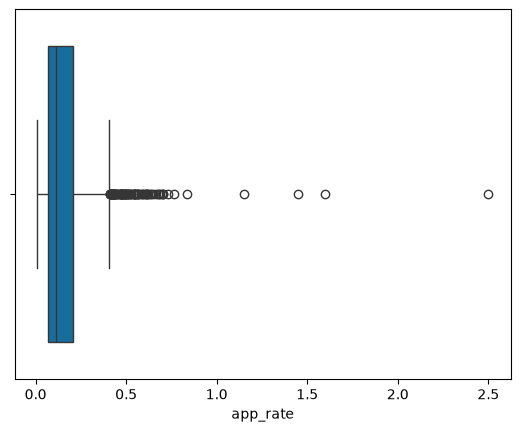

In [70]:
sns.boxplot(hs_enroll.to_pandas(),x = 'app_rate')

<Axes: xlabel='app_rate', ylabel='Count'>

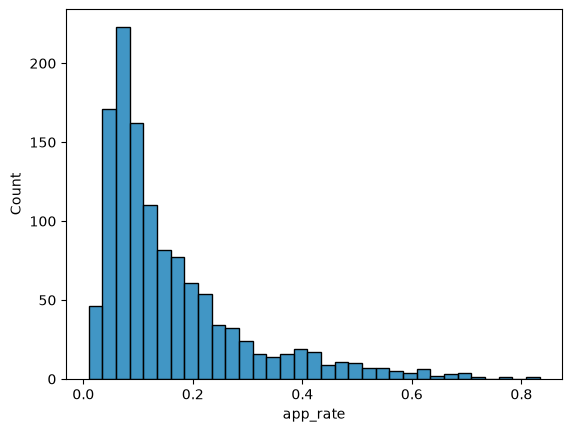

In [72]:
sns.histplot(hs_enroll.to_pandas(),x = 'app_rate')